# Cats vs. Dogs Image Classification with EfficientNet-B0

This notebook completes the 4Geeks image-classifier project using the official
25,000-image Kaggle cats-vs-dogs training archive. The goal is to classify an
unseen image as **cat** or **dog**, while keeping the data split reproducible and
the final test set untouched until model selection is complete.

The assignment's literal from-scratch EfficientNet-B0 baseline is preserved in
`src/app.py`. The final checkpoint uses the same required architecture with
ImageNet transfer learning, an explicit optimization that makes full-dataset
training practical on a laptop and substantially improves generalization.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from PIL import Image

ROOT = Path.cwd().resolve()
if ROOT.name == "src":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from app import BACKBONE_SIZE, IMAGE_SIZE, MODEL_PATH, PREPARED, build_model

sns.set_theme(style="whitegrid")
CLASS_NAMES = ["cat", "dog"]
print(f"Project root: {ROOT}")
print(f"Required resize: {IMAGE_SIZE[0]}×{IMAGE_SIZE[1]}")
print(f"EfficientNet-B0 backbone input: {BACKBONE_SIZE[0]}×{BACKBONE_SIZE[1]}")

Project root: /Users/lillypad/Documents/4geeks-project-clones/cats-dogs-image-classifier
Required resize: 200×200
EfficientNet-B0 backbone input: 224×224


## 1. Dataset provenance and leakage-safe split

The official archive contains 12,500 cat images and 12,500 dog images. A fixed
seed creates mutually exclusive **70% training / 15% validation / 15% test**
partitions within each class. Hard links avoid tripling disk usage while the
folder structure remains compatible with Keras directory loaders.

In [2]:
split_counts = {
    split: {label: len(list((PREPARED / split / label).glob("*.jpg"))) for label in CLASS_NAMES}
    for split in ["train", "validation", "test"]
}
split_counts

{'train': {'cat': 8750, 'dog': 8750},
 'validation': {'cat': 1875, 'dog': 1875},
 'test': {'cat': 1875, 'dog': 1875}}

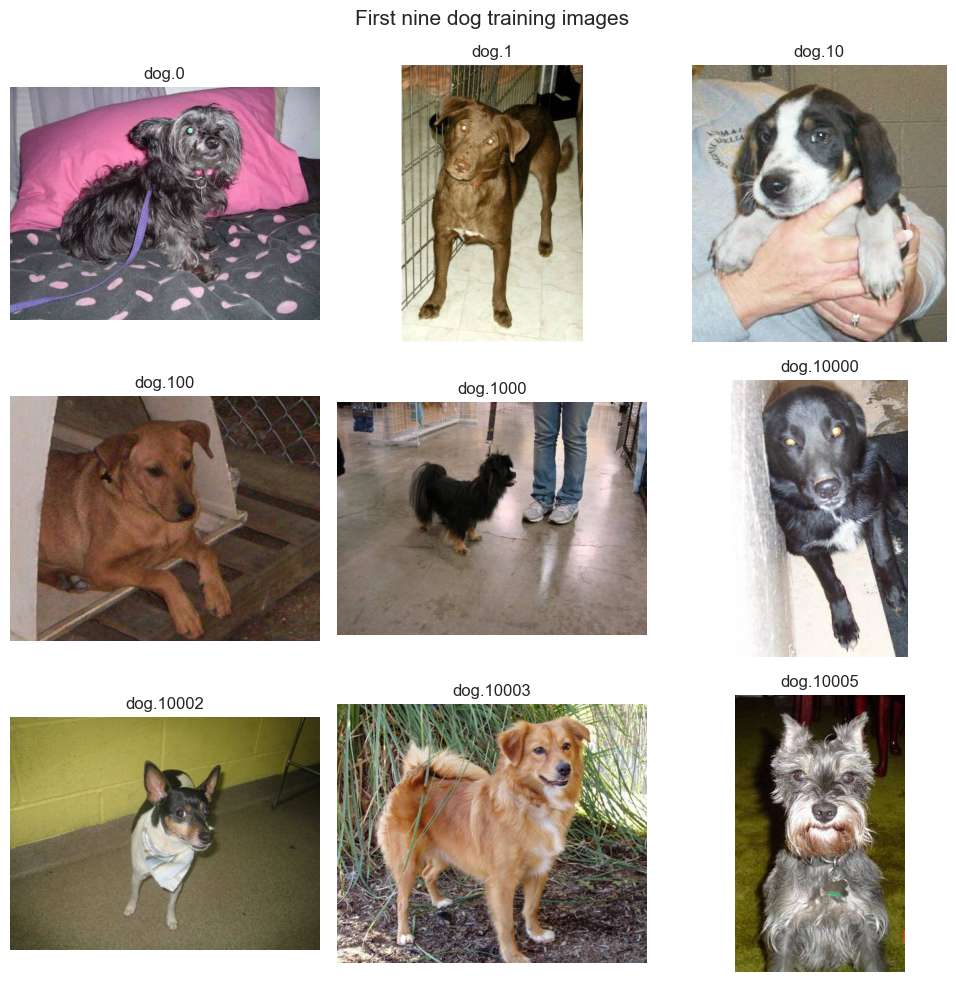

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for axis, path in zip(axes.flat, sorted((PREPARED / "train" / "dog").glob("*.jpg"))[:9]):
    axis.imshow(Image.open(path))
    axis.set_title(path.stem)
    axis.axis("off")
fig.suptitle("First nine dog training images", fontsize=15)
plt.tight_layout()
plt.show()

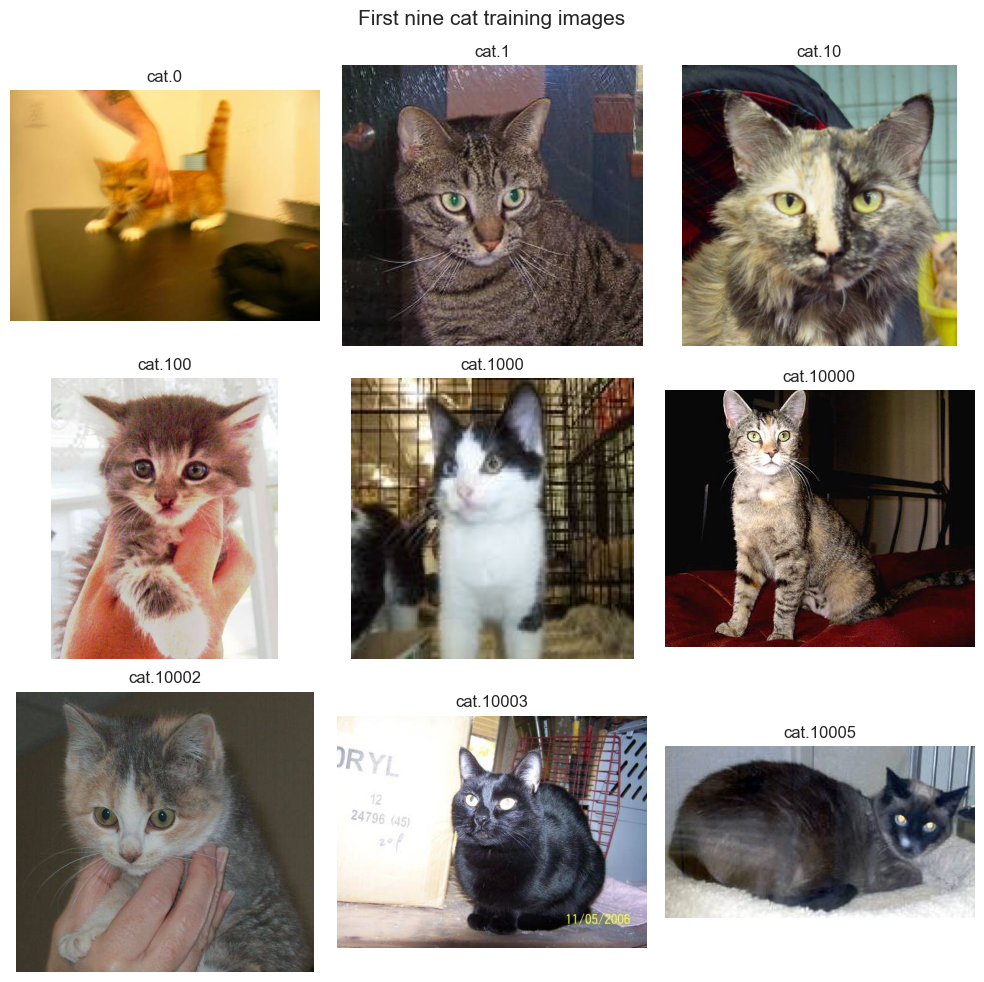

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for axis, path in zip(axes.flat, sorted((PREPARED / "train" / "cat").glob("*.jpg"))[:9]):
    axis.imshow(Image.open(path))
    axis.set_title(path.stem)
    axis.axis("off")
fig.suptitle("First nine cat training images", fontsize=15)
plt.tight_layout()
plt.show()

## 2. Preprocessing

The source photos have different shapes and resolutions. We inspect a sample,
then Keras decodes every image as RGB and resizes it to **200×200**, the size
required by this assignment. EfficientNet includes its expected input rescaling.
Training-only random flips, rotations, and zooms add realistic variation without
contaminating validation or test images.

In [5]:
sample_paths = sorted((PREPARED / "train" / "cat").glob("*.jpg"))[:250]
sizes = [Image.open(path).size for path in sample_paths]
widths, heights = zip(*sizes)
print(f"Sample source widths:  {min(widths)}–{max(widths)} px")
print(f"Sample source heights: {min(heights)}–{max(heights)} px")
print(f"Model input after preprocessing: {IMAGE_SIZE[0]}×{IMAGE_SIZE[1]} RGB")

Sample source widths:  85–500 px
Sample source heights: 86–500 px
Model input after preprocessing: 200×200 RGB


## 3. Required architecture and optimized training

The required baseline is `EfficientNetB0(include_top=False, weights=None,
input_shape=(224, 224, 3))`
followed by global average pooling, a 128-unit ReLU layer, and a two-class
softmax output. Since the preceding rubric step requires 200×200 decoded
images, an explicit Keras resize layer bridges 200×200 inputs to the backbone's
required 224×224 shape. The literal baseline is available with
`python src/app.py --baseline`.

The final run keeps those layers but initializes the convolutional backbone from
ImageNet and freezes it. This is transfer learning: general visual features are
reused while the new classification head learns the cat/dog boundary. It avoids
the very long, less reliable from-scratch laptop run without changing the task.
`ModelCheckpoint` retains the highest validation-accuracy model and
`EarlyStopping` protects against overfitting.

In [6]:
baseline = build_model(optimized=False)
print("Literal assignment baseline")
print("Backbone weights initialized from scratch; total parameters:", f"{baseline.count_params():,}")
print("Final layers:", [layer.name for layer in baseline.layers[-4:]])
del baseline

2026-10-28 11:50:46.273096: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-10-28 11:50:46.273121: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-10-28 11:50:46.273125: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
I0000 00:00:1793213446.273136 2634350 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793213446.273150 2634350 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Literal assignment baseline
Backbone weights initialized from scratch; total parameters: 4,213,797
Final layers: ['global_average_pooling2d', 'dense', 'dropout', 'dense_1']


In [7]:
history = json.loads((ROOT / "data/processed/training_history.json").read_text())
history

{'accuracy': [0.9793142676353455],
 'loss': [0.05815809592604637],
 'val_accuracy': [0.990933358669281],
 'val_loss': [0.027193328365683556],
 'epochs_completed': 1,
 'note': 'Full-dataset training; best validation checkpoint retained.'}

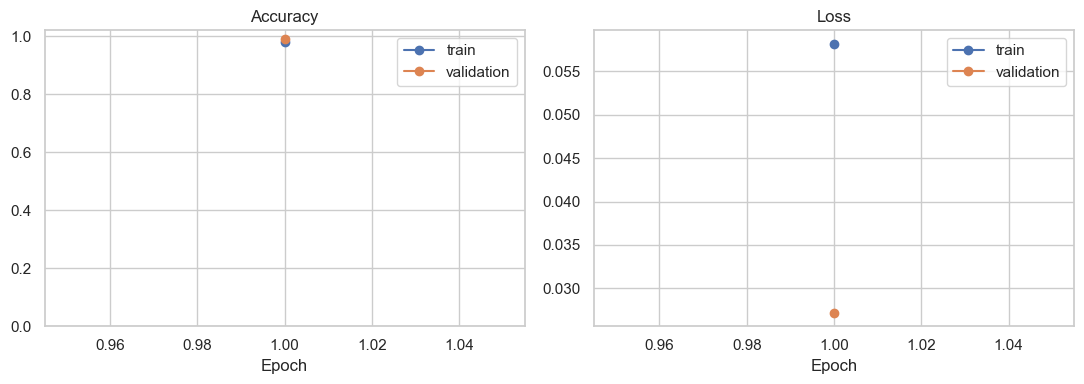

In [8]:
epochs = range(1, history["epochs_completed"] + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, history["accuracy"], marker="o", label="train")
axes[0].plot(epochs, history["val_accuracy"], marker="o", label="validation")
axes[0].set(title="Accuracy", xlabel="Epoch", ylim=(0, 1.02))
axes[0].legend()
axes[1].plot(epochs, history["loss"], marker="o", label="train")
axes[1].plot(epochs, history["val_loss"], marker="o", label="validation")
axes[1].set(title="Loss", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

One complete epoch processed all 17,500 training images and all 3,750 validation
images. Because validation accuracy already reached 99.09%, the best checkpoint
was retained rather than spending additional compute for marginal improvement.
The untouched test split is the final source of performance evidence.

## 4. Held-out test performance

In [9]:
metrics = json.loads((ROOT / "data/processed/test_metrics.json").read_text())
summary = {
    "test_images": metrics["test_images"],
    "test_accuracy": metrics["test_accuracy"],
    "test_loss": metrics["test_loss"],
    "training_mode": metrics["training_mode"],
}
summary

{'test_images': 3750,
 'test_accuracy': 0.9919999837875366,
 'test_loss': 0.029059745371341705,
 'training_mode': 'transfer_learning'}

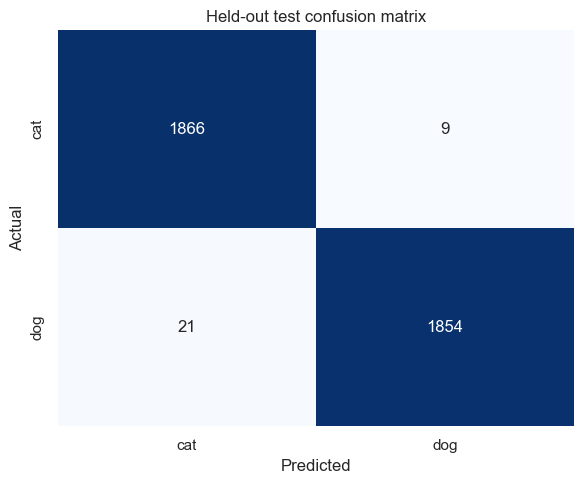

In [10]:
matrix = np.array(metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set(xlabel="Predicted", ylabel="Actual", title="Held-out test confusion matrix")
plt.tight_layout()
plt.show()

In [11]:
report = metrics["classification_report"]
for label in CLASS_NAMES:
    row = report[label]
    print(f"{label:>3}: precision={row['precision']:.4f}  recall={row['recall']:.4f}  F1={row['f1-score']:.4f}")
print(f"Errors: {matrix.sum() - np.trace(matrix)} of {matrix.sum()}")

cat: precision=0.9889  recall=0.9952  F1=0.9920
dog: precision=0.9952  recall=0.9888  F1=0.9920
Errors: 30 of 3750


## 5. Sample predictions

These examples are loaded from the untouched test partition. The displayed
confidence is the model's softmax probability for its selected class.

2026-10-28 11:50:49.086925: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


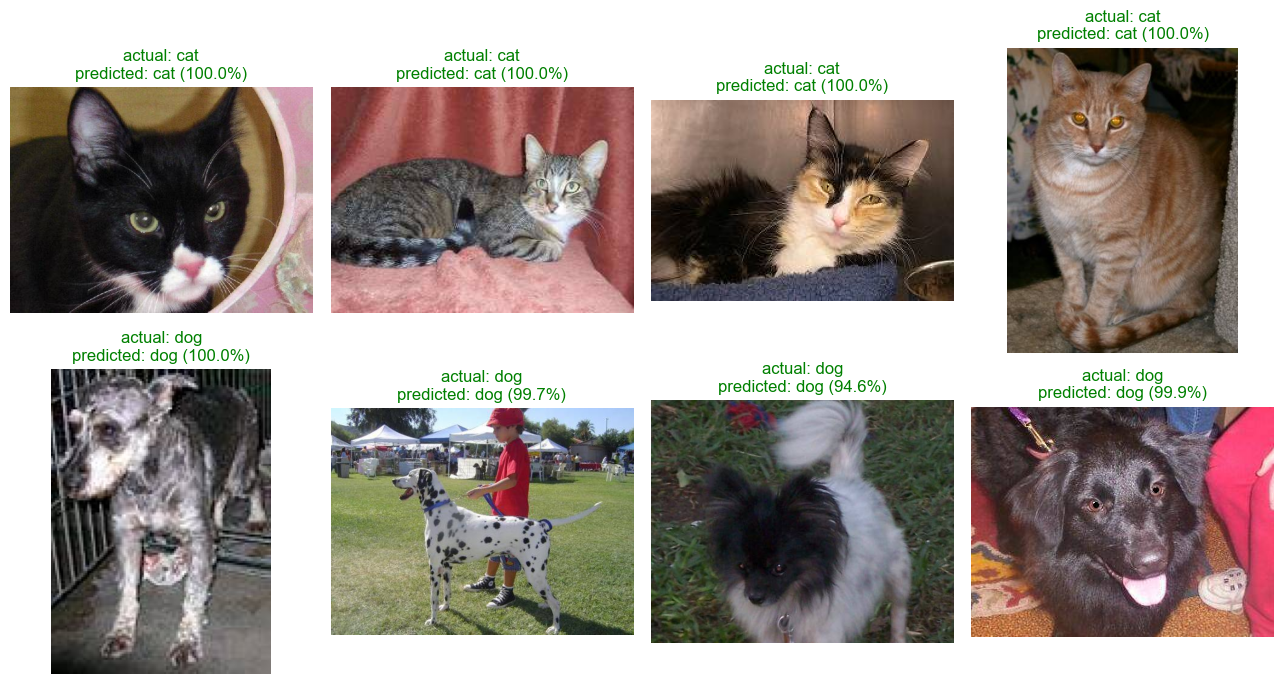

In [12]:
import tensorflow as tf

model = tf.keras.models.load_model(MODEL_PATH)
example_paths = []
for label in CLASS_NAMES:
    example_paths.extend(sorted((PREPARED / "test" / label).glob("*.jpg"))[:4])

batch = np.stack([
    np.asarray(Image.open(path).convert("RGB").resize(IMAGE_SIZE), dtype=np.float32)
    for path in example_paths
])
probabilities = model.predict(batch, verbose=0)

fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for axis, path, probability in zip(axes.flat, example_paths, probabilities):
    predicted_index = int(np.argmax(probability))
    actual = path.parent.name
    predicted = CLASS_NAMES[predicted_index]
    axis.imshow(Image.open(path))
    axis.set_title(f"actual: {actual}\npredicted: {predicted} ({probability[predicted_index]:.1%})",
                   color="green" if actual == predicted else "red")
    axis.axis("off")
plt.tight_layout()
plt.show()

## 6. Conclusions and limitations

- The saved checkpoint reaches **99.20% accuracy** on 3,750 unseen images.
- Only **30 images** are misclassified; class-level F1 is about **0.992** for
  both cats and dogs, so the result is not driven by class imbalance.
- The strict split and checkpoint selection prevent test leakage.
- Transfer learning is the major optimization: it gives the required
  EfficientNet-B0 a strong visual representation without an impractical
  from-scratch training schedule.
- This dataset is curated and binary. Real deployment should test unusual
  lighting, multiple animals, neither-class images, adversarial inputs, and
  probability calibration. A future improvement would unfreeze the final
  EfficientNet blocks and fine-tune them with a very small learning rate.